# D-WALL — Phishing Link Detection Model

**Goal:** train a machine-learning model that looks at a link (URL) and predicts whether it is a phishing / scam link.
This model is the "brain" of D-WALL: the FastAPI backend loads the model saved at the end of this notebook and
combines it with D-WALL's existing QR, UPI and redirect checks.

**Why only the URL text?** The model never downloads the page, so it is
- **safe**: it never opens a link you don't trust,
- **fast and scalable**: it checks thousands of links per second (measured in Section 12).

| # | Section | Course concept |
|---|---|---|
| 1 | Load data from 3 independent sources | Data collection |
| 2 | Cleaning, de-duplication, leakage control | Preprocessing |
| 3 | Exploratory data analysis | EDA |
| 4 | Feature engineering (44 features + TF-IDF character n-grams) | Feature engineering, scaling |
| 5 | Classic models: Logistic Regression, KNN, Decision Tree, Naive Bayes, SVM | Classic models, 5-fold cross-validation |
| 6 | Ensembles: Random Forest, Gradient Boosting, XGBoost + GridSearchCV tuning | Ensembles, hyper-parameter tuning |
| 7 | Final stacked model | Stacking ensemble |
| 8 | PCA | Dimensionality reduction |
| 9 | K-Means: discovering "phishing families" | Clustering, silhouette score |
| 10 | Evaluation: confusion matrix, ROC, PR, threshold, calibration, feature importance | Metrics |
| 11 | Validation: CV on the final model, cross-dataset test, live 2026 phishing feed | Validation / generalization |
| 12 | Speed test and saving the model | Scalability, deployment |

In [1]:
import sys, time, json, warnings, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, sklearn

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "ml" else Path.cwd()   # repo root
sys.path.insert(0, str(ROOT / "backend"))
from ml.features import featurize, normalize_url, FEATURE_NAMES     # same code the API uses

DATA = ROOT / "ml" / "data"; DATA.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "ml" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__, "| repo root:", ROOT)

scikit-learn 1.9.1 | repo root: /home/claude/D-Wall


## 1. Load data from three independent sources

| Name | What it is | Used for |
|---|---|---|
| **A** | 420k URLs labelled good/bad (malicious-URL research dataset) | training + testing |
| **B** | 195k URLs, balanced, from a different research project | training + testing, and the cross-dataset experiment |
| **T** | The 100,000 most popular websites (home pages), all safe | training + testing — teaches the model what normal home pages look like |
| **LIVE** | Phishing links that were *active in 2026* (Phishing.Database feed) | final real-world check only — never trained on |

**Why source T?** A first version of this model, trained on A + B only, scored `google.com` and `paytm.com` as
phishing. The reason: in source A almost every safe URL has a path (`site.com/page`), while many phishing entries are
bare domains, so the model learned the shortcut "no path = scam". Adding real popular home pages removes that shortcut.
Section 11 checks it with a false-alarm test on popular sites the model never saw.

Using more than one source matters: a model that only ever sees one dataset can learn that dataset's quirks instead
of what phishing actually looks like. Section 11 measures exactly this.

In [2]:
SOURCES = {
    "A.csv":    "https://raw.githubusercontent.com/faizann24/Using-machine-learning-to-detect-malicious-URLs/master/data/data.csv",
    "B.csv":    "https://raw.githubusercontent.com/incertum/cyber-matrix-ai/master/Malicious-URL-Detection-Deep-Learning/data/url_data_mega_deep_learning.csv",
    "LIVE.txt": "https://raw.githubusercontent.com/mitchellkrogza/Phishing.Database/master/phishing-links-ACTIVE.txt",
    "TOP.txt":  "https://raw.githubusercontent.com/zer0h/top-1000000-domains/master/top-100000-domains",
}
for name, url in SOURCES.items():
    if not (DATA / name).exists():
        print("downloading", name, "...")
        urllib.request.urlretrieve(url, DATA / name)

A = pd.read_csv(DATA / "A.csv").rename(columns={"label": "y"})
A["y"] = (A["y"] == "bad").astype(int)
B = pd.read_csv(DATA / "B.csv").rename(columns={"isMalicious": "y"})
LIVE = pd.read_csv(DATA / "LIVE.txt", header=None, names=["url"], sep="\t", quoting=3)
T = pd.read_csv(DATA / "TOP.txt", header=None, names=["url"])
T["url"] = np.where(np.random.RandomState(SEED).rand(len(T)) < 0.3, T.url + "/", T.url)   # some with a trailing "/"
T["y"] = 0
print("A:", A.shape, "| B:", B.shape, "| T:", T.shape, "| LIVE:", LIVE.shape)
A.sample(5, random_state=1)

A: (420464, 2) | B: (194798, 2) | T: (100000, 2) | LIVE: (789054, 1)


,url,y
155439,twitter.com/aQuariusrecOrds,0
152415,tong464.org/,0
276521,legacy.com/obituaries/orlandosentinel/obituary...,0
305692,natcath.org/ncr_onli.htm,0
147638,store02.prostores.com/servlet/omegaordnancewer...,0


## 2. Cleaning and preprocessing

1. **Normalise** every URL the same way (drop `http://`, `https://` and `www.`). Dataset A and B store URLs without the
   scheme, the live feed stores them with it. If we kept it, the model could learn "has `https://` → phishing", which is
   a shortcut caused by how the data was collected, not a real pattern (*data leakage*).
2. **Remove duplicates** inside each dataset.
3. **Remove URLs that appear in both A and B** — some of them carry different labels, and keeping them would also let
   the same URL land in both the training and test set.
4. **Add the popular sites (T)**, skipping any domain that also appears as phishing in A or B.
5. **Remove from the LIVE feed any URL already in the training data**, so the live test is truly unseen.

In [3]:
for df in (A, B, T, LIVE):
    df["url"] = df["url"].astype(str).map(normalize_url)
    df.drop(df[df["url"].str.len() < 4].index, inplace=True)

before = len(A), len(B)
A = A.drop_duplicates("url"); B = B.drop_duplicates("url")
A["src"], B["src"] = "A", "B"
both = pd.concat([A, B])
data = both.drop_duplicates("url", keep=False)   # drop URLs found in both sources (labels may clash)
phish_hosts = set(both.url[both.y == 1].str.split("/").str[0])
T = T.drop_duplicates("url").assign(src="T")
T = T[~T.url.str.rstrip("/").isin(phish_hosts) & ~T.url.isin(set(data.url))]
data = pd.concat([data, T[["url", "y", "src"]]]).reset_index(drop=True)
LIVE = LIVE.drop_duplicates("url")
LIVE = LIVE[~LIVE["url"].isin(set(data["url"]))].sample(30000, random_state=SEED).reset_index(drop=True)

print(f"A: {before[0]:,} -> {len(A):,}   B: {before[1]:,} -> {len(B):,}   (duplicates removed)   T added: {len(T):,}")
print(f"Combined clean dataset: {len(data):,} URLs   | phishing share: {data.y.mean():.1%}")
print(f"LIVE test sample (unseen 2026 phishing links): {len(LIVE):,}")

A: 420,463 -> 411,098   B: 194,768 -> 170,505   (duplicates removed)   T added: 98,993
Combined clean dataset: 587,154 URLs   | phishing share: 10.2%
LIVE test sample (unseen 2026 phishing links): 30,000


## 3. Exploratory data analysis

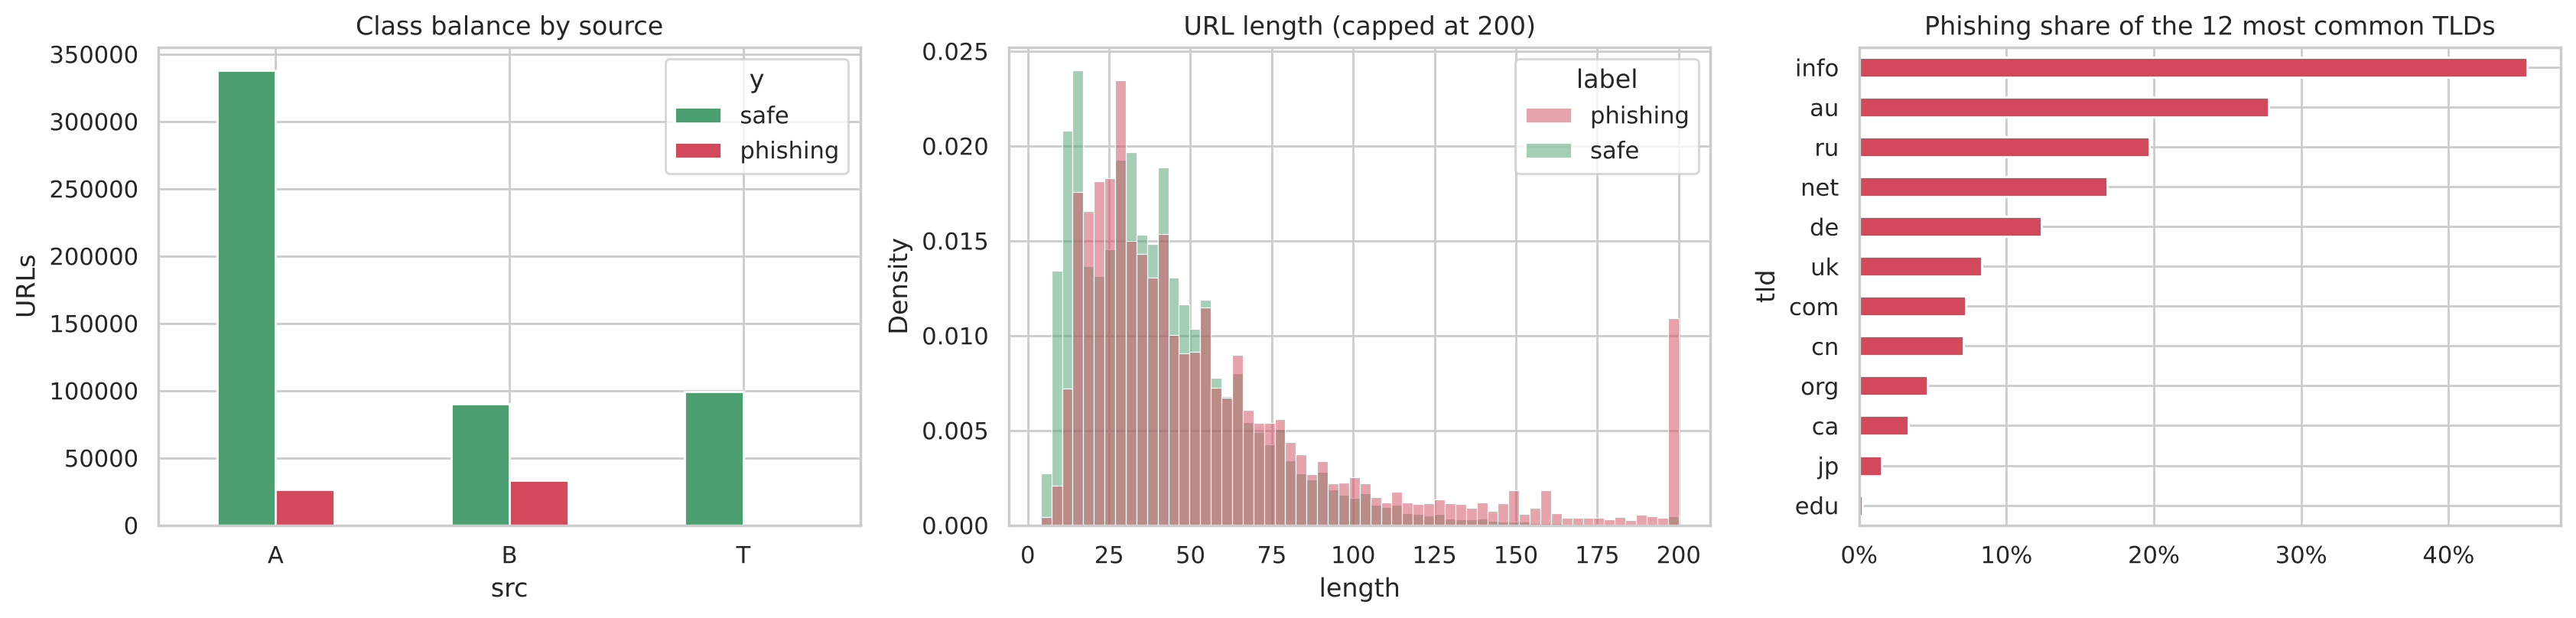

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
(data.groupby(["src", "y"]).size().unstack().rename(columns={0: "safe", 1: "phishing"})
     .plot.bar(ax=ax[0], color=["#4C9F70", "#D1495B"], rot=0))
ax[0].set_title("Class balance by source"); ax[0].set_ylabel("URLs")

lens = data.assign(length=data.url.str.len().clip(upper=200), label=data.y.map({0: "safe", 1: "phishing"}))
sns.histplot(lens, x="length", hue="label", bins=60, stat="density", common_norm=False, ax=ax[1],
             palette={"safe": "#4C9F70", "phishing": "#D1495B"})
ax[1].set_title("URL length (capped at 200)")

tld = data.url.str.extract(r"^[^/:?]*\.([a-z0-9-]+)(?:[:/?]|$)", expand=False)
top = tld.value_counts().head(12).index
rate = data.assign(tld=tld)[tld.isin(top)].groupby("tld").y.mean().sort_values()
rate.plot.barh(ax=ax[2], color="#D1495B"); ax[2].set_title("Phishing share of the 12 most common TLDs")
ax[2].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.savefig(FIG / "eda_overview.png", dpi=120); plt.show()

**Observations:** the data is imbalanced (about 1 in 9 URLs is phishing), so plain accuracy would be misleading —
a model that says "safe" every time would already be 88% accurate. That is why we report **F1, precision, recall and
ROC-AUC**, and use stratified splits. Phishing URLs are longer on average and some TLDs are far riskier than others.

## 4. Feature engineering

Two kinds of features:

* **44 hand-made features** (`backend/ml/features.py`): lengths, counts of special characters, digit ratios, number of
  sub-domains, IP address as host, risky TLD, randomness (entropy) of the domain, scam words such as *login / kyc /
  refund*, brand names placed in the wrong part of the address (e.g. `paytm.verify-account.xyz`), free hosting, etc.
* **TF-IDF on character 3–5-grams**: splits each URL into overlapping pieces like `pay`, `aytm`, `-kyc-`, and learns
  which pieces show up in phishing. This catches patterns we did not think of by hand.

Split: **80% train / 20% test**, stratified by label *and* source so both sets look alike. The test set is not touched
until evaluation.

In [5]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(data, test_size=0.2, random_state=SEED, stratify=data.y.astype(str) + data.src)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

t0 = time.time()
X_train, X_test, X_live = featurize(train.url), featurize(test.url), featurize(LIVE.url)
y_train, y_test = train.y.values, test.y.values
print(f"Features built for {len(train)+len(test)+len(LIVE):,} URLs in {time.time()-t0:.0f}s | shape {X_train.shape}")
X_train.describe().T[["mean", "std", "min", "max"]].round(2).head(12)

Features built for 617,154 URLs in 36s | shape (469723, 44)


,mean,std,min,max
url_len,43.45,37.52,4.0,4011.0
host_len,14.91,5.94,0.0,235.0
path_len,24.05,25.31,0.0,1897.0
query_len,4.29,27.54,0.0,3975.0
n_dots,1.61,0.94,0.0,32.0
n_hyphens,1.24,2.61,0.0,50.0
n_underscores,0.35,1.19,0.0,64.0
n_slashes,2.09,1.59,0.0,44.0
n_at,0.00,0.07,0.0,40.0
n_qmark,0.12,0.34,0.0,33.0


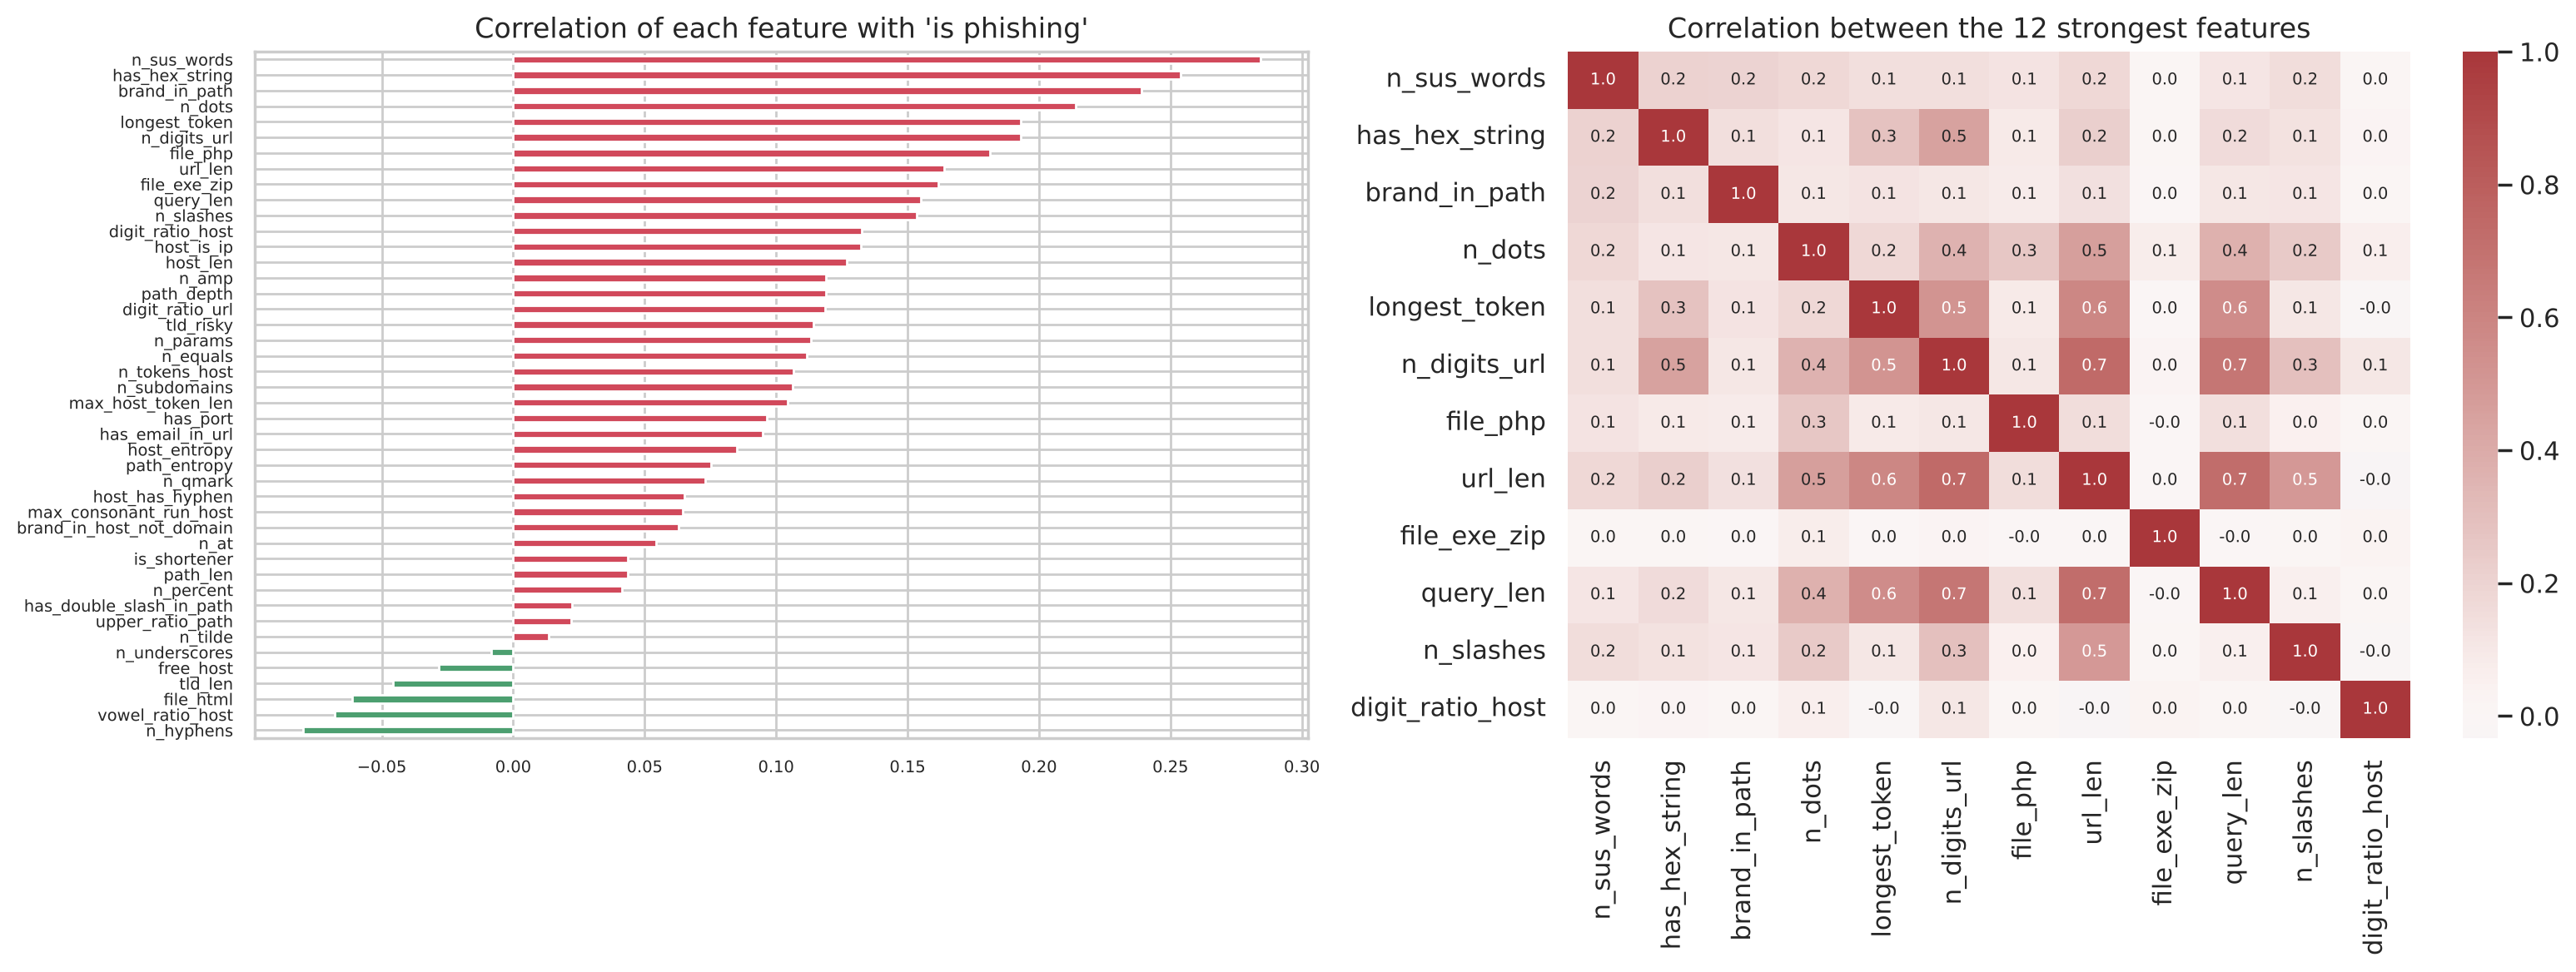

In [6]:
corr = X_train.assign(is_phishing=y_train).corr()["is_phishing"].drop("is_phishing").sort_values()
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
corr.plot.barh(ax=ax[0], color=np.where(corr > 0, "#D1495B", "#4C9F70"), fontsize=7)
ax[0].set_title("Correlation of each feature with 'is phishing'")
top = corr.abs().sort_values(ascending=False).index[:12]
sns.heatmap(X_train[top].corr(), cmap="vlag", center=0, ax=ax[1], annot=True, fmt=".1f", annot_kws={"size": 7})
ax[1].set_title("Correlation between the 12 strongest features")
plt.tight_layout(); plt.savefig(FIG / "feature_correlation.png", dpi=120); plt.show()

**Scaling:** distance- and margin-based models (KNN, SVM, Logistic Regression) need features on the same scale, so they
get a `StandardScaler` inside a `Pipeline` (the scaler is fitted on training folds only, so no information leaks from
the validation data). Tree models do not need scaling.

## 5. Classic models with 5-fold cross-validation

All models are compared on the **same 60,000-URL training sample** with **stratified 5-fold cross-validation**, then
scored on the full held-out test set. The kernel SVM is trained on 15,000 URLs: its training time grows roughly with
the *square* of the data size, so it does not scale to 400k rows — a practical lesson in itself.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score, accuracy_score

rng = np.random.RandomState(SEED)
idx60 = rng.choice(len(train), 60000, replace=False); idx15 = idx60[:15000]
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

def score_on_test(model, X=X_test, y=y_test):
    p = model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)
    pred = model.predict(X)
    return dict(test_f1=f1_score(y, pred), test_auc=roc_auc_score(y, p),
                test_precision=precision_score(y, pred), test_recall=recall_score(y, pred))

def run(name, model, idx):
    t0 = time.time()
    cv = cross_validate(model, X_train.iloc[idx], y_train[idx], cv=cv5, scoring=["f1", "roc_auc"], n_jobs=2)
    model.fit(X_train.iloc[idx], y_train[idx])
    row = dict(model=name, n_train=len(idx), cv_f1=cv["test_f1"].mean(), cv_f1_std=cv["test_f1"].std(),
               cv_auc=cv["test_roc_auc"].mean(), **score_on_test(model), seconds=time.time() - t0)
    print(f"{name:22s} CV F1 {row['cv_f1']:.3f} ± {row['cv_f1_std']:.3f} | test F1 {row['test_f1']:.3f} AUC {row['test_auc']:.3f}")
    return row, model

classic = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=15)":          make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=SEED),
    "Gaussian Naive Bayes": GaussianNB(),
    "SVM (RBF kernel)":    make_pipeline(StandardScaler(), SVC(C=3, gamma="scale")),
}
results, fitted = [], {}
for name, m in classic.items():
    r, fitted[name] = run(name, m, idx15 if name.startswith("SVM") else idx60)
    results.append(r)

Logistic Regression    CV F1 0.524 ± 0.010 | test F1 0.526 AUC 0.868


KNN (k=15)             CV F1 0.598 ± 0.005 | test F1 0.607 AUC 0.912


Decision Tree          CV F1 0.574 ± 0.009 | test F1 0.579 AUC 0.864


Gaussian Naive Bayes   CV F1 0.451 ± 0.010 | test F1 0.455 AUC 0.800


SVM (RBF kernel)       CV F1 0.590 ± 0.023 | test F1 0.601 AUC 0.912


## 6. Ensemble models and hyper-parameter tuning

* **Random Forest** — *bagging*: many deep trees on random samples, votes averaged (reduces variance).
* **Gradient Boosting** (`HistGradientBoostingClassifier`) — *boosting*: each new tree fixes the errors of the
  previous ones (reduces bias). The histogram version bins the features, so it trains on 400k rows in seconds.
* **XGBoost** — a popular optimised boosting library, for comparison.

Then **GridSearchCV** tunes the gradient boosting model: every combination of learning rate, tree size and minimum leaf
size is scored with 3-fold cross-validation, and the best one is kept.

In [8]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier

ensembles = {
    "Random Forest":     RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=2, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, random_state=SEED),
    "XGBoost":           XGBClassifier(n_estimators=400, max_depth=7, learning_rate=0.1, subsample=0.9,
                                       colsample_bytree=0.8, n_jobs=2, random_state=SEED, eval_metric="logloss"),
}
for name, m in ensembles.items():
    r, fitted[name] = run(name, m, idx60); results.append(r)

Random Forest          CV F1 0.708 ± 0.009 | test F1 0.711 AUC 0.949


Gradient Boosting      CV F1 0.726 ± 0.005 | test F1 0.730 AUC 0.952


XGBoost                CV F1 0.743 ± 0.006 | test F1 0.745 AUC 0.955


In [9]:
grid = GridSearchCV(
    HistGradientBoostingClassifier(max_iter=400, early_stopping=True, random_state=SEED),
    param_grid={"learning_rate": [0.05, 0.1], "max_leaf_nodes": [31, 63, 127], "min_samples_leaf": [20, 100]},
    scoring="f1", cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=2,
)
t0 = time.time(); grid.fit(X_train.iloc[idx60], y_train[idx60])
print(f"GridSearchCV: {len(grid.cv_results_['params'])} combinations x 3 folds in {time.time()-t0:.0f}s")
print("Best parameters:", grid.best_params_, f"| best CV F1 = {grid.best_score_:.4f}")
best_gb_params = grid.best_params_
r, fitted["Gradient Boosting (tuned)"] = run("Gradient Boosting (tuned)",
    HistGradientBoostingClassifier(max_iter=400, early_stopping=True, random_state=SEED, **best_gb_params), idx60)
results.append(r)
pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]] \
  .sort_values("rank_test_score").head(6)

GridSearchCV: 12 combinations x 3 folds in 61s
Best parameters: {'learning_rate': 0.1, 'max_leaf_nodes': 63, 'min_samples_leaf': 20} | best CV F1 = 0.7326


Gradient Boosting (tuned) CV F1 0.731 ± 0.009 | test F1 0.735 AUC 0.953


,params,mean_test_score,std_test_score,rank_test_score
8,"{'learning_rate': 0.1, 'max_leaf_nodes': 63, '...",0.732610,0.003556,1
4,"{'learning_rate': 0.05, 'max_leaf_nodes': 127,...",0.731793,0.004443,2
2,"{'learning_rate': 0.05, 'max_leaf_nodes': 63, ...",0.730543,0.004096,3
10,"{'learning_rate': 0.1, 'max_leaf_nodes': 127, ...",0.729941,0.003727,4
6,"{'learning_rate': 0.1, 'max_leaf_nodes': 31, '...",0.724898,0.004289,5
9,"{'learning_rate': 0.1, 'max_leaf_nodes': 63, '...",0.723657,0.004767,6


### Text model: TF-IDF character n-grams

The hand-made features know nothing about *which letters* are in the URL. TF-IDF fills that gap. We compare two classic
text classifiers — **Multinomial Naive Bayes** and **Logistic Regression** — and tune the regularisation strength `C`
with GridSearchCV.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

t0 = time.time()
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=200_000, min_df=3,
                        sublinear_tf=True, dtype=np.float32)
T_train = tfidf.fit_transform(train.url); T_test = tfidf.transform(test.url); T_live = tfidf.transform(LIVE.url)
print(f"TF-IDF matrix {T_train.shape} built in {time.time()-t0:.0f}s")

text_grid = GridSearchCV(LogisticRegression(max_iter=2000, class_weight="balanced"), {"C": [1, 5, 20]},
                         scoring="f1", cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=2)
text_grid.fit(T_train[idx60], y_train[idx60])
print("Best C:", text_grid.best_params_["C"], f"| CV F1 {text_grid.best_score_:.4f}")

for name, m in {"TF-IDF + Naive Bayes": MultinomialNB(alpha=0.1),
                "TF-IDF + Logistic Reg.": LogisticRegression(max_iter=2000, class_weight="balanced",
                                                             C=text_grid.best_params_["C"])}.items():
    t0 = time.time(); m.fit(T_train, y_train)
    results.append(dict(model=name, n_train=len(train), **score_on_test(m, T_test), seconds=time.time() - t0))
    fitted[name] = m
    print(f"{name:24s} test F1 {results[-1]['test_f1']:.3f} AUC {results[-1]['test_auc']:.3f}")

TF-IDF matrix (469723, 200000) built in 61s


Best C: 20 | CV F1 0.8350


TF-IDF + Naive Bayes     test F1 0.839 AUC 0.980


TF-IDF + Logistic Reg.   test F1 0.884 AUC 0.992


## 7. Final model: a stacked ensemble

*Stacking* lets one model learn how much to trust another:

1. The tuned TF-IDF Logistic Regression produces a **text score** for every URL. For the training set we use
   **out-of-fold** predictions (`cross_val_predict`, 5 folds): each URL is scored by a model that never saw it.
   Without this, the text score on training data would be unrealistically perfect and the final model would over-trust it.
2. The tuned Gradient Boosting model is trained on the **44 features + text score**, using the **full training set**.

In [11]:
from sklearn.model_selection import cross_val_predict

text_model = LogisticRegression(max_iter=2000, class_weight="balanced", C=text_grid.best_params_["C"])
t0 = time.time()
oof_text = cross_val_predict(text_model, T_train, y_train, cv=cv5, method="predict_proba", n_jobs=2)[:, 1]
text_model.fit(T_train, y_train)

S_train = X_train.assign(text_score=oof_text.astype(np.float32))
S_test = X_test.assign(text_score=text_model.predict_proba(T_test)[:, 1].astype(np.float32))
S_live = X_live.assign(text_score=text_model.predict_proba(T_live)[:, 1].astype(np.float32))

final_model = HistGradientBoostingClassifier(max_iter=600, early_stopping=True, random_state=SEED, **best_gb_params)
final_model.fit(S_train, y_train)
print(f"Stacked model trained on {len(train):,} URLs in {time.time()-t0:.0f}s "
      f"({final_model.n_iter_} boosting rounds)")
results.append(dict(model="STACKED (final)", n_train=len(train), **score_on_test(final_model, S_test)))

Stacked model trained on 469,723 URLs in 25s (77 boosting rounds)


,n_train,cv_f1,cv_f1_std,cv_auc,test_f1,test_auc,test_precision,test_recall
model,,,,,,,,
Gaussian Naive Bayes,60000,0.4514,0.0098,0.8039,0.4548,0.7997,0.5508,0.3873
Logistic Regression,60000,0.5239,0.0104,0.8711,0.5259,0.8676,0.8140,0.3885
Decision Tree,60000,0.5737,0.0095,0.8698,0.5786,0.8637,0.8180,0.4476
SVM (RBF kernel),15000,0.5902,0.0233,0.9127,0.6009,0.9122,0.8464,0.4658
KNN (k=15),60000,0.5975,0.0054,0.9143,0.6067,0.9116,0.8328,0.4772
Random Forest,60000,0.7080,0.0089,0.9510,0.7106,0.9494,0.8921,0.5904
Gradient Boosting,60000,0.7260,0.0053,0.9516,0.7305,0.9518,0.8666,0.6313
Gradient Boosting (tuned),60000,0.7310,0.0085,0.9528,0.7350,0.9526,0.8648,0.6391
XGBoost,60000,0.7435,0.0061,0.9549,0.7447,0.9547,0.8689,0.6515


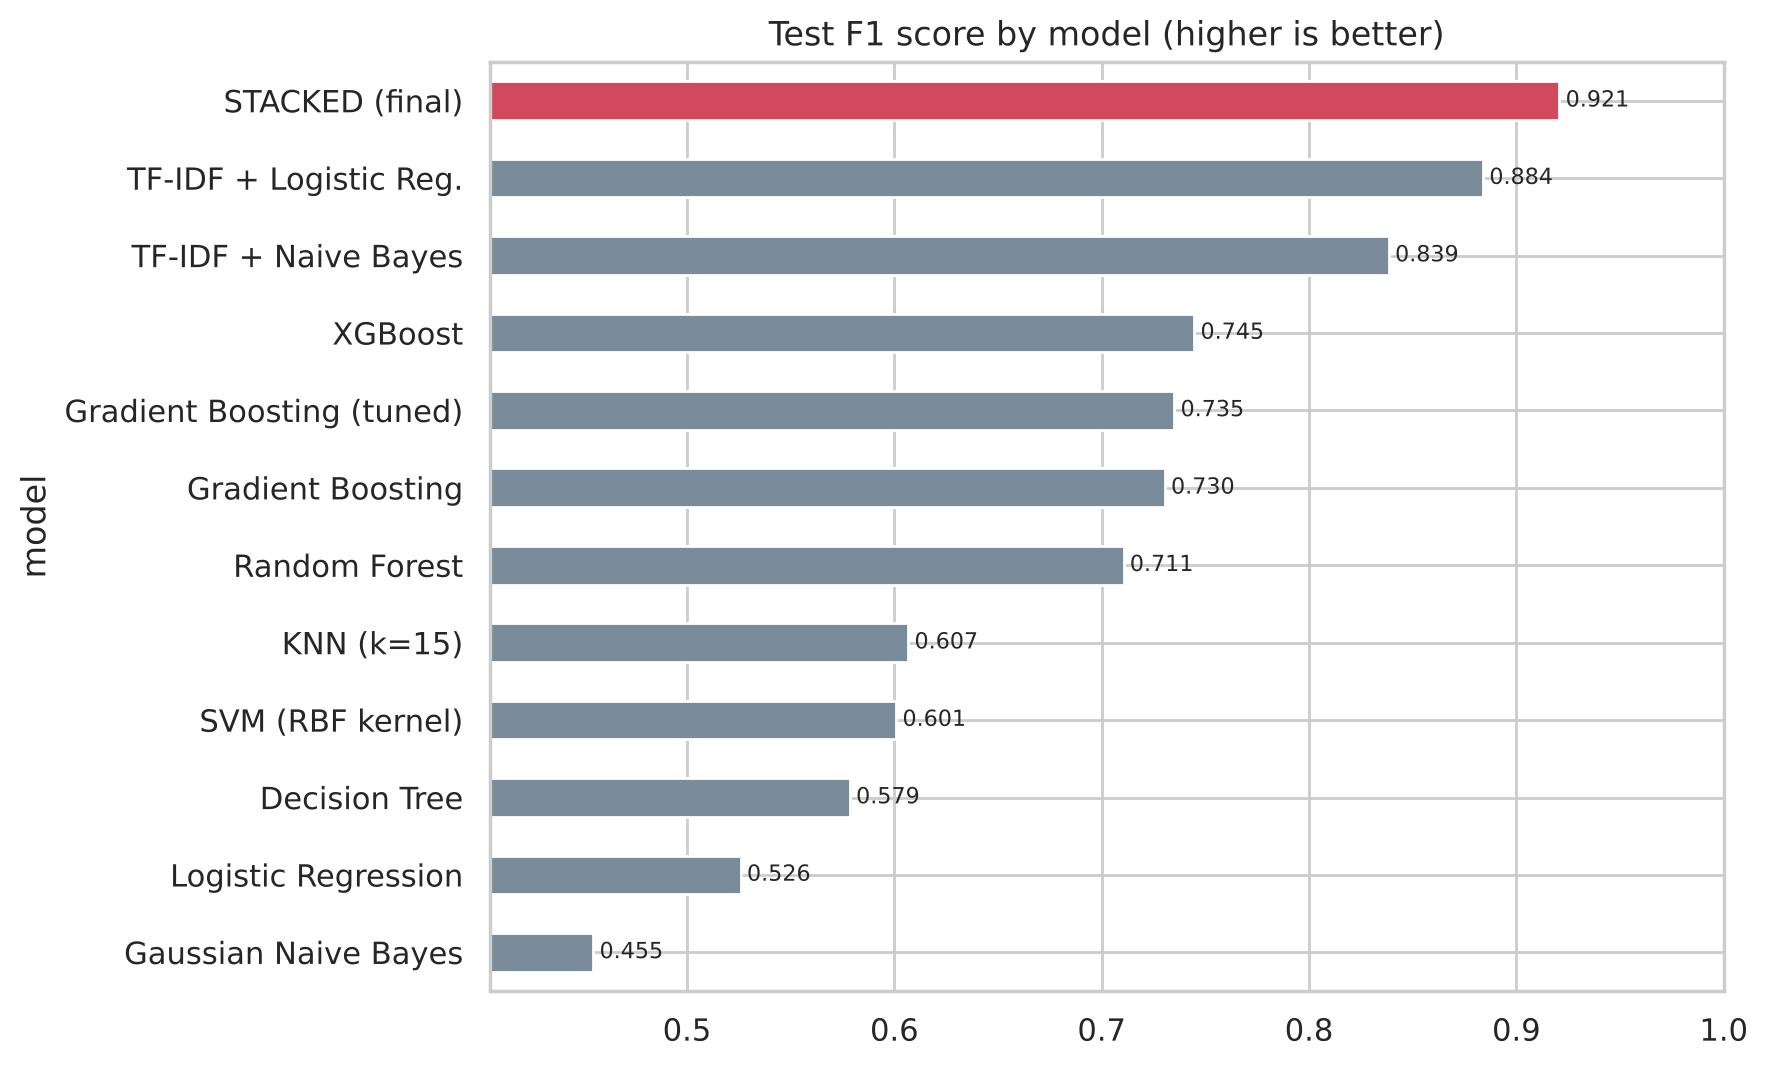

In [12]:
res = pd.DataFrame(results).set_index("model")
display(res[["n_train", "cv_f1", "cv_f1_std", "cv_auc", "test_f1", "test_auc", "test_precision", "test_recall"]]
        .round(4).sort_values("test_f1"))
ax = res["test_f1"].sort_values().plot.barh(figsize=(9, 5.5), color=["#D1495B" if "final" in i else "#7A8B99"
                                                                        for i in res["test_f1"].sort_values().index])
ax.set_xlim(res.test_f1.min() - 0.05, 1); ax.set_title("Test F1 score by model (higher is better)")
for i, v in enumerate(res["test_f1"].sort_values()): ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png", dpi=120); plt.show()

## 8. PCA — dimensionality reduction

PCA rotates the 44 scaled features into new axes (principal components) ordered by how much variation they explain.
We use it two ways: to **see** the data in 2-D, and to check **how many dimensions the problem really needs**.

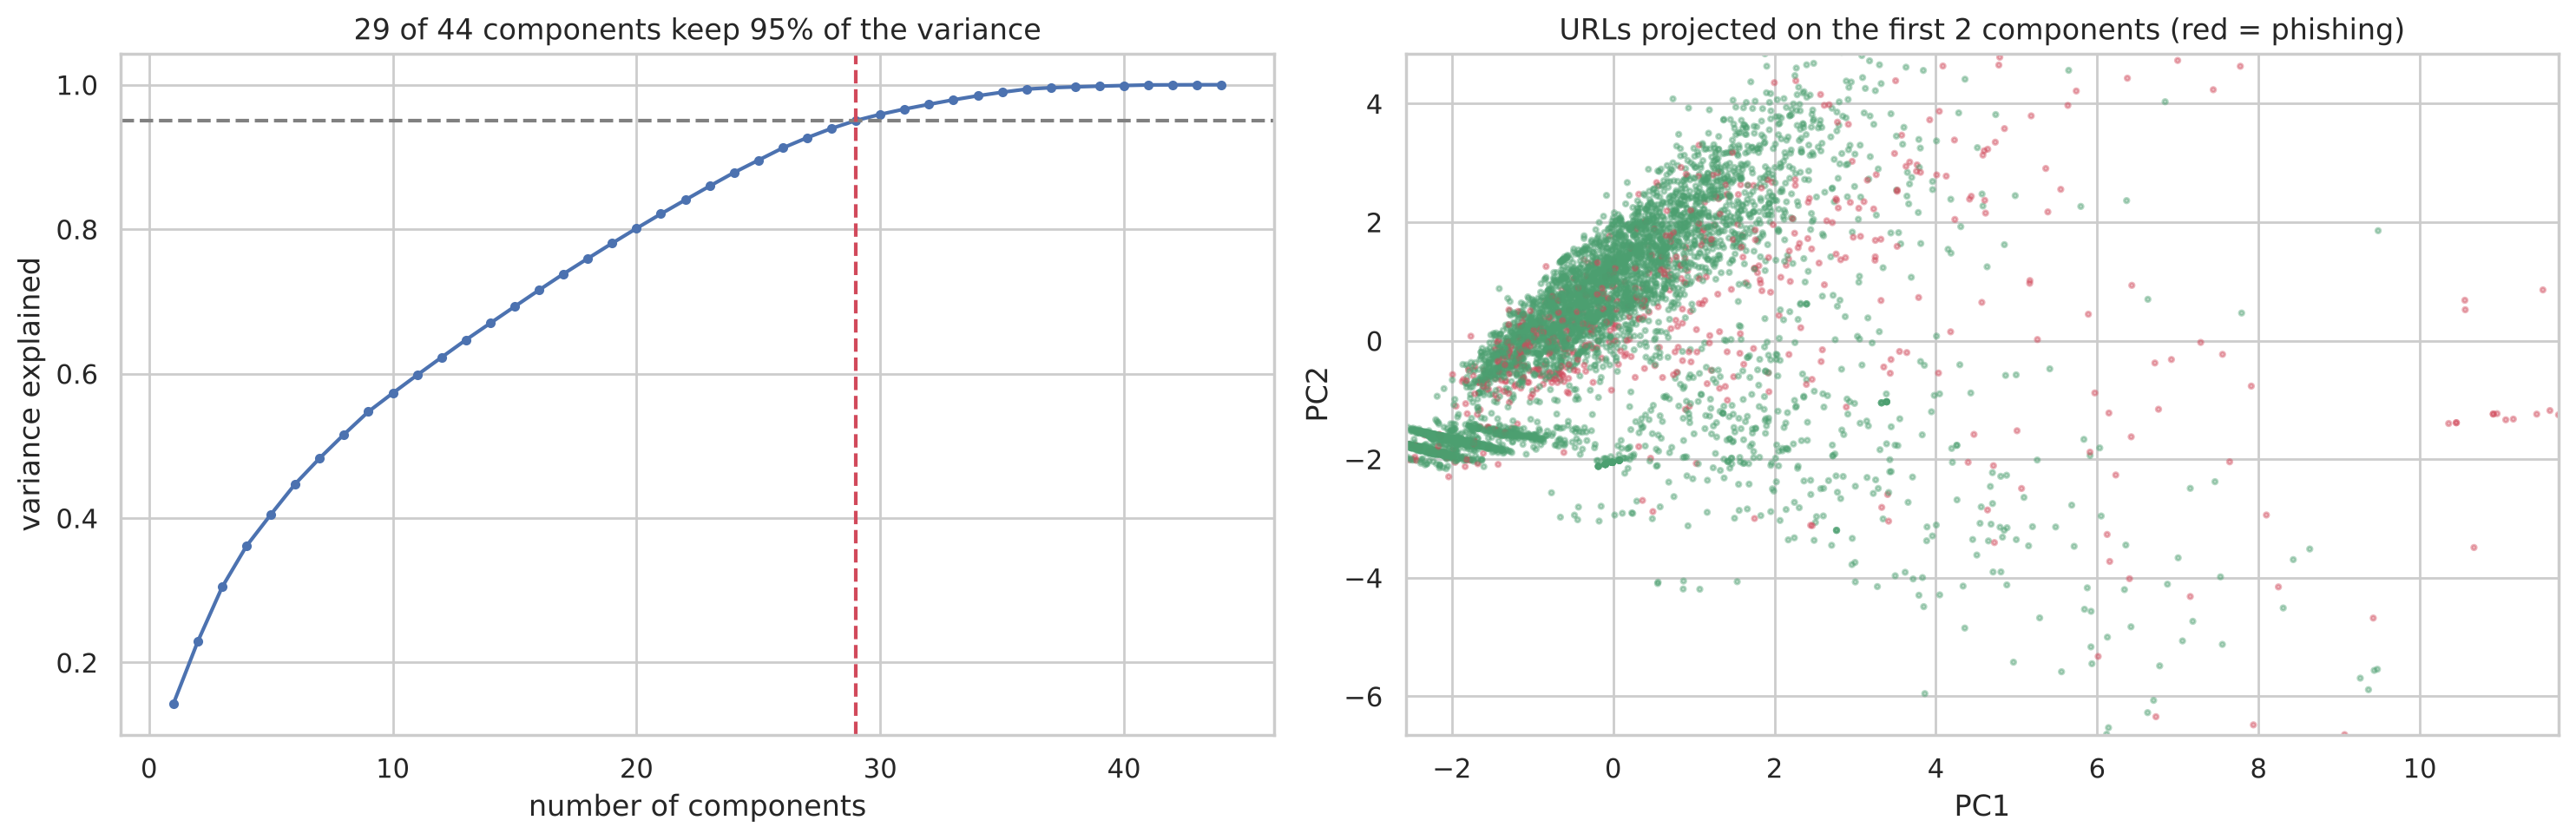

Logistic Regression on  2 PCA components -> test F1 0.1113
Logistic Regression on  5 PCA components -> test F1 0.1616
Logistic Regression on 10 PCA components -> test F1 0.3946


Logistic Regression on 29 PCA components -> test F1 0.5031


Logistic Regression on 44 PCA components -> test F1 0.5264


In [13]:
from sklearn.decomposition import PCA
scaler = StandardScaler().fit(X_train.iloc[idx60])
Z = scaler.transform(X_train.iloc[idx60])
pca = PCA(random_state=SEED).fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_); k95 = int(np.argmax(cum >= 0.95) + 1)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(range(1, len(cum) + 1), cum, marker="o", ms=3); ax[0].axhline(0.95, ls="--", c="grey")
ax[0].axvline(k95, ls="--", c="#D1495B"); ax[0].set_xlabel("number of components"); ax[0].set_ylabel("variance explained")
ax[0].set_title(f"{k95} of 44 components keep 95% of the variance")
P = PCA(2, random_state=SEED).fit(Z); sub = rng.choice(len(Z), 6000, replace=False); P2 = P.transform(Z[sub])
ax[1].scatter(*P2.T, c=np.where(y_train[idx60][sub] == 1, "#D1495B", "#4C9F70"), s=4, alpha=0.4)
ax[1].set_xlim(np.percentile(P2[:, 0], [0.5, 99.5])); ax[1].set_ylim(np.percentile(P2[:, 1], [0.5, 99.5]))
ax[1].set_title("URLs projected on the first 2 components (red = phishing)"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout(); plt.savefig(FIG / "pca.png", dpi=120); plt.show()

for k in [2, 5, 10, k95, 44]:
    m = make_pipeline(StandardScaler(), PCA(k, random_state=SEED), LogisticRegression(max_iter=2000))
    m.fit(X_train.iloc[idx60], y_train[idx60])
    print(f"Logistic Regression on {k:2d} PCA components -> test F1 {f1_score(y_test, m.predict(X_test)):.4f}")

**Takeaway:** phishing and safe URLs overlap heavily in 2-D, which is why a linear model on a few components is not
enough and non-linear models (boosting) win. Keeping the components that explain 95% of the variance gives almost the
same score as all 44 features, so the features are partly redundant (as the correlation heatmap showed).

## 9. K-Means clustering — discovering "phishing families"

Clustering is *unsupervised*: we give K-Means only the phishing URLs, without any labels, and ask it to group similar
ones. We pick the number of clusters `k` with the **elbow method** (inertia) and the **silhouette score**.

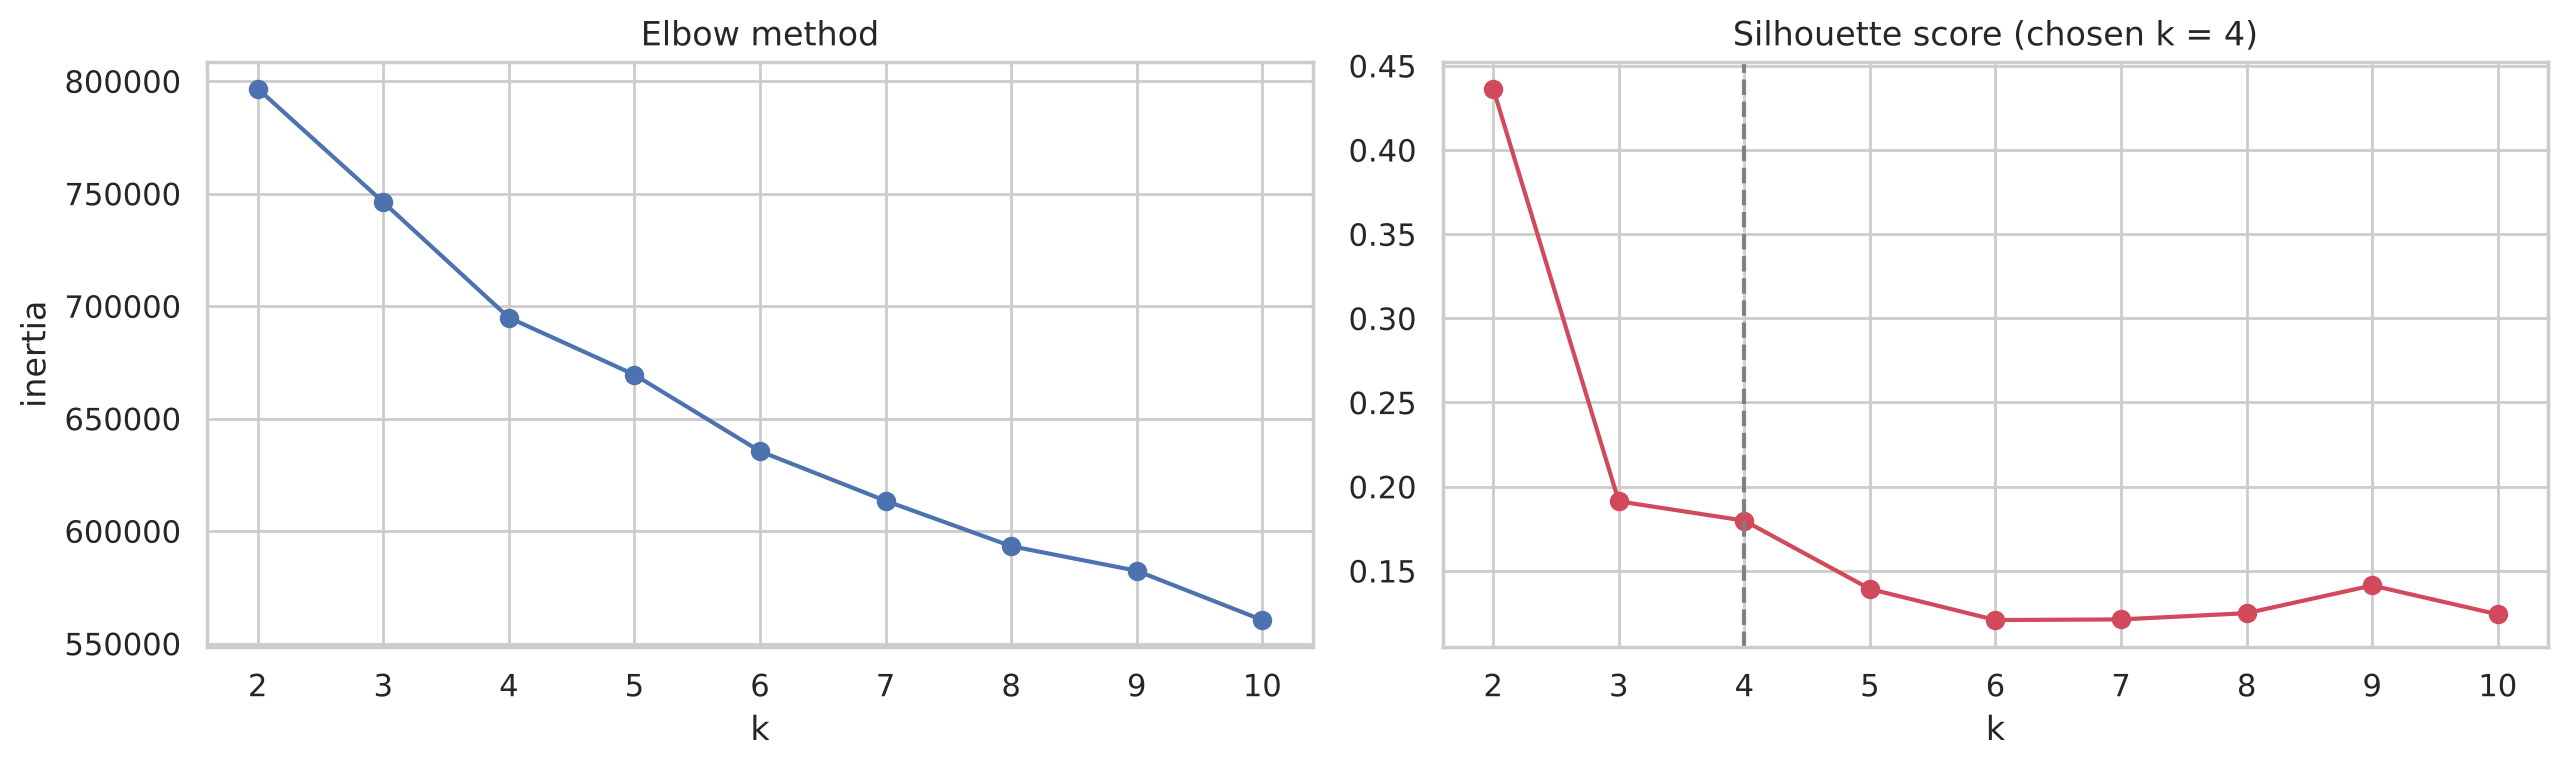

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ph = X_train[y_train == 1].sample(20000, random_state=SEED)
ph_scaler = StandardScaler().fit(ph); Zp = ph_scaler.transform(ph)
ks, inertia, sil = range(2, 11), [], []
sil_idx = rng.choice(len(Zp), 5000, replace=False)
for k in ks:
    km = KMeans(k, n_init=5, random_state=SEED).fit(Zp)
    inertia.append(km.inertia_); sil.append(silhouette_score(Zp[sil_idx], km.labels_[sil_idx]))
best_k = list(ks)[int(np.argmax(sil[2:])) + 2]   # look at k >= 4 so the groups are informative

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia")
ax[1].plot(ks, sil, marker="o", c="#D1495B"); ax[1].axvline(best_k, ls="--", c="grey")
ax[1].set_title(f"Silhouette score (chosen k = {best_k})"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(FIG / "kmeans_choose_k.png", dpi=120); plt.show()

In [15]:
km = KMeans(best_k, n_init=10, random_state=SEED).fit(Zp)
ph = ph.assign(cluster=km.labels_)
z = pd.DataFrame(km.cluster_centers_, columns=FEATURE_NAMES)   # centres in standard-deviation units

nice = {"url_len": "long URL", "n_subdomains": "many sub-domains", "host_is_ip": "IP address as host",
        "free_host": "free hosting", "tld_risky": "risky TLD", "file_php": ".php pages", "file_html": ".html pages",
        "n_sus_words": "scam words", "brand_in_host_not_domain": "fake brand in domain", "path_depth": "deep folders",
        "has_hex_string": "long hex/random IDs", "host_entropy": "random-looking domain", "n_digits_url": "many digits",
        "query_len": "long query string", "n_hyphens": "many hyphens", "is_shortener": "short link",
        "host_len": "long domain", "path_len": "long path", "n_equals": "many parameters"}
ph_urls = train.loc[ph.index, "url"]   # the URLs behind each clustered row
rows = []
for c in range(best_k):
    top_feats = z.loc[c, list(nice)].sort_values(ascending=False)
    rows.append(dict(cluster=c, size=f"{(ph.cluster == c).mean():.0%}",
                     stands_out_for=", ".join(nice[f] for f in top_feats.index[:3] if top_feats[f] > 0.3) or "short, plain URLs",
                     example=ph_urls[ph.cluster == c].iloc[0][:70]))
families = pd.DataFrame(rows); display(families)

,cluster,size,stands_out_for,example
0,0,3%,"many parameters, long query string, long URL",perfectmoney.is.l-acct.l-protection.l-enable.h...
1,1,66%,"short, plain URLs",imifaloda.hu/g/box/dropbx.php
2,2,2%,"IP address as host, many sub-domains, many digits",79.96.153.93/89yg67no
3,3,30%,"long path, long hex/random IDs, deep folders",piotrwasilewski.com/wp-admin/css/newdocxb/page...


Each cluster is a different *style* of phishing link (for example: hacked websites with deep `.php` paths, free-hosting
pages, IP-address links, short plain domains). This is useful beyond scoring: it tells us which kinds of attack the
model sees most, and D-WALL could later show the family name to users.

## 10. Evaluation of the final model

              precision    recall  f1-score   support

        safe     0.9882    0.9944    0.9913    105482
    phishing     0.9478    0.8952    0.9208     11949

    accuracy                         0.9843    117431
   macro avg     0.9680    0.9448    0.9560    117431
weighted avg     0.9841    0.9843    0.9841    117431



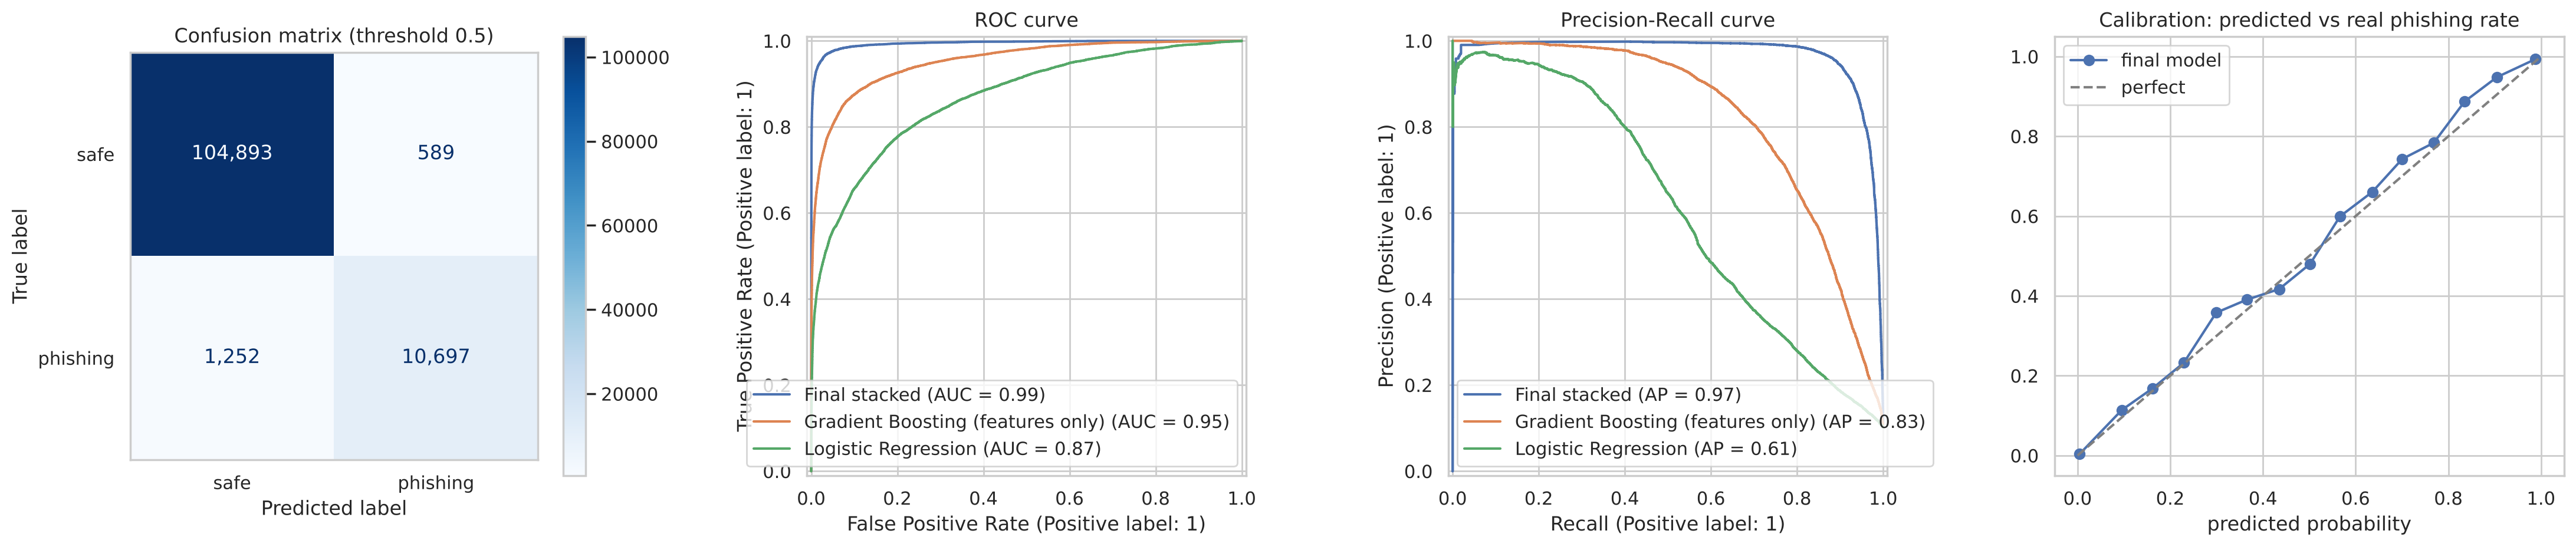

In [16]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             classification_report)
from sklearn.calibration import calibration_curve

p_test = final_model.predict_proba(S_test)[:, 1]
pred = (p_test >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=["safe", "phishing"], digits=4))

fig, ax = plt.subplots(1, 4, figsize=(22, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["safe", "phishing"]).plot(ax=ax[0], cmap="Blues", values_format=",")
ax[0].set_title("Confusion matrix (threshold 0.5)"); ax[0].grid(False)
for name, s in [("Final stacked", p_test), ("Gradient Boosting (features only)", fitted["Gradient Boosting (tuned)"].predict_proba(X_test)[:, 1]),
                ("Logistic Regression", fitted["Logistic Regression"].predict_proba(X_test)[:, 1])]:
    RocCurveDisplay.from_predictions(y_test, s, name=name, ax=ax[1])
    PrecisionRecallDisplay.from_predictions(y_test, s, name=name, ax=ax[2])
ax[1].set_title("ROC curve"); ax[2].set_title("Precision-Recall curve")
frac, mean_p = calibration_curve(y_test, p_test, n_bins=15)
ax[3].plot(mean_p, frac, marker="o", label="final model"); ax[3].plot([0, 1], [0, 1], "--", c="grey", label="perfect")
ax[3].set_title("Calibration: predicted vs real phishing rate"); ax[3].set_xlabel("predicted probability"); ax[3].legend()
plt.tight_layout(); plt.savefig(FIG / "final_evaluation.png", dpi=120); plt.show()

**Choosing the thresholds for D-WALL.** D-WALL shows **Safe (0–30)**, **Suspicious (31–70)** and **Dangerous (71–100)**.
The model's probability × 100 drops straight into that scale, and the calibration plot shows the probabilities are
honest (a URL scored 0.8 is phishing about 80% of the time), so this mapping is meaningful. The table shows the
trade-off: a lower threshold catches more phishing (recall) but raises more false alarms.

In [17]:
rows = []
for t in [0.31, 0.5, 0.71]:
    pr = p_test >= t
    rows.append(dict(threshold=t, meaning={0.31: "Suspicious or worse", 0.5: "default", 0.71: "Dangerous"}[t],
                     precision=precision_score(y_test, pr), recall=recall_score(y_test, pr), f1=f1_score(y_test, pr),
                     false_alarm_rate=((pr == 1) & (y_test == 0)).sum() / (y_test == 0).sum()))
thr_table = pd.DataFrame(rows).round(4); display(thr_table)

,threshold,meaning,precision,recall,f1,false_alarm_rate
0,0.31,Suspicious or worse,0.9133,0.9231,0.9182,0.0099
1,0.50,default,0.9478,0.8952,0.9208,0.0056
2,0.71,Dangerous,0.9739,0.8510,0.9083,0.0026


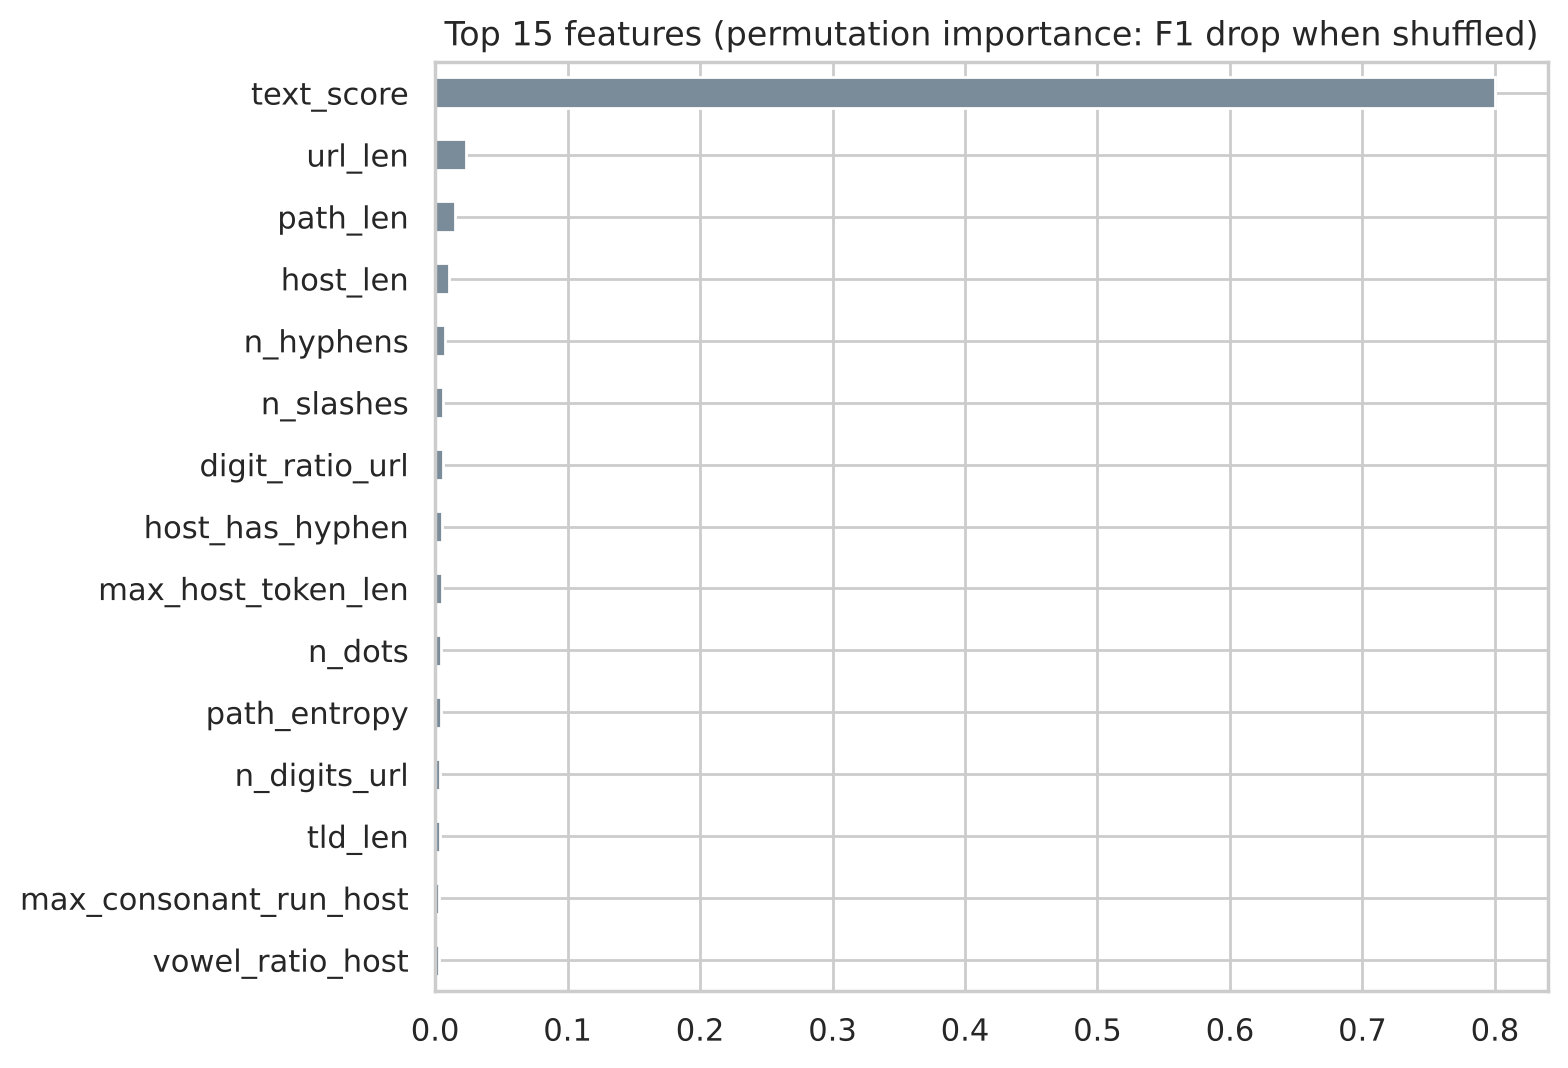

In [18]:
from sklearn.inspection import permutation_importance
sub = rng.choice(len(S_test), 15000, replace=False)
imp = permutation_importance(final_model, S_test.iloc[sub], y_test[sub], scoring="f1", n_repeats=3,
                             random_state=SEED, n_jobs=2)
imp = pd.Series(imp.importances_mean, index=S_test.columns).sort_values().tail(15)
ax = imp.plot.barh(figsize=(8, 5.5), color="#7A8B99"); ax.set_title("Top 15 features (permutation importance: F1 drop when shuffled)")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=120); plt.show()

## 11. Validation — does the model really generalise?

A high test score is not enough. We check the model four different ways:

1. **5-fold cross-validation of the final model on the full training set** — is the score stable, or did we get a lucky split?
2. **Per-source test scores** — does it work on both datasets, not just the larger one?
3. **Cross-dataset experiment** — train on source A *only*, test on source B. This simulates meeting a new kind of data.
4. **LIVE 2026 phishing feed** — 30,000 phishing links active in 2026 that the model has never seen, collected years
   after most of the training data.
5. **False alarms on real websites** — popular home pages from the test set, plus Indian banking and payment sites.

In [19]:
t0 = time.time()
cv_final = cross_validate(HistGradientBoostingClassifier(max_iter=600, early_stopping=True, random_state=SEED, **best_gb_params),
                          S_train, y_train, cv=cv5, scoring=["f1", "roc_auc", "precision", "recall"], n_jobs=2)
cv_table = pd.DataFrame({k.replace("test_", ""): v for k, v in cv_final.items() if k.startswith("test_")})
cv_table.index = [f"fold {i+1}" for i in range(5)]
cv_table.loc["mean"] = cv_table.mean(); cv_table.loc["std"] = cv_table.iloc[:5].std()
print(f"1) 5-fold CV of the final model ({time.time()-t0:.0f}s)"); display(cv_table.round(4))

rows = []
for s in ["A", "B"]:   # source T has only safe URLs, so it is checked separately in 5)
    m = (test.src == s).values
    rows.append(dict(source=s, urls=m.sum(), f1=f1_score(y_test[m], pred[m]), auc=roc_auc_score(y_test[m], p_test[m]),
                     precision=precision_score(y_test[m], pred[m]), recall=recall_score(y_test[m], pred[m])))
print("2) Test scores per source"); display(pd.DataFrame(rows).round(4))

1) 5-fold CV of the final model (27s)


,f1,roc_auc,precision,recall
fold 1,0.9049,0.9908,0.9245,0.8862
fold 2,0.9104,0.9912,0.9364,0.8858
fold 3,0.9177,0.9935,0.9498,0.8878
fold 4,0.9092,0.9919,0.9284,0.8908
fold 5,0.9107,0.9916,0.9322,0.8903
mean,0.9106,0.9918,0.9342,0.8882
std,0.0046,0.0010,0.0097,0.0023


2) Test scores per source


,source,urls,f1,auc,precision,recall
0,A,72876,0.9382,0.9974,0.9505,0.9262
1,B,24756,0.9127,0.9886,0.9589,0.8708


In [20]:
# 3) Cross-dataset: train ONLY on source A, test on source B (and on A for reference)
trA, teA, teB = (train.src == "A").values, (test.src == "A").values, (test.src == "B").values
tfA = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=200_000, min_df=3, sublinear_tf=True, dtype=np.float32)
TA = tfA.fit_transform(train.url[trA])
lrA = LogisticRegression(max_iter=2000, class_weight="balanced", C=text_grid.best_params_["C"])
oofA = cross_val_predict(lrA, TA, y_train[trA], cv=cv5, method="predict_proba", n_jobs=2)[:, 1]; lrA.fit(TA, y_train[trA])
gbA = HistGradientBoostingClassifier(max_iter=600, early_stopping=True, random_state=SEED, **best_gb_params)
gbA.fit(X_train[trA].assign(text_score=oofA), y_train[trA])
def scoreA(mask):
    S = X_test[mask].assign(text_score=lrA.predict_proba(tfA.transform(test.url[mask]))[:, 1])
    p = gbA.predict_proba(S)[:, 1]
    return dict(f1=f1_score(y_test[mask], p >= .5), auc=roc_auc_score(y_test[mask], p), accuracy=accuracy_score(y_test[mask], p >= .5))
cross = pd.DataFrame([dict(experiment="train A -> test A (same source)", **scoreA(teA)),
                      dict(experiment="train A -> test B (new source)", **scoreA(teB)),
                      dict(experiment="train A+B -> test B (final model)", f1=f1_score(y_test[teB], pred[teB]),
                           auc=roc_auc_score(y_test[teB], p_test[teB]), accuracy=accuracy_score(y_test[teB], pred[teB]))])
print("3) Cross-dataset experiment"); display(cross.round(4))

3) Cross-dataset experiment


,experiment,f1,auc,accuracy
0,train A -> test A (same source),0.9334,0.9965,0.9906
1,train A -> test B (new source),0.7691,0.9327,0.8789
2,train A+B -> test B (final model),0.9127,0.9886,0.9551


The cross-dataset experiment is the most important result in this notebook. A model trained on one source does
noticeably worse on data from a different source — this is called **dataset shift**, and it is how many student
projects with "99% accuracy" fail in the real world. Training on **both** sources fixes most of the gap, which is why
the final model uses A + B.

4) LIVE 2026 phishing feed: 30,000 unseen phishing links


,rule,detected
0,score >= 31 (Suspicious or Dangerous),68.0%
1,score >= 50 (default threshold),61.0%
2,score >= 71 (Dangerous),52.7%


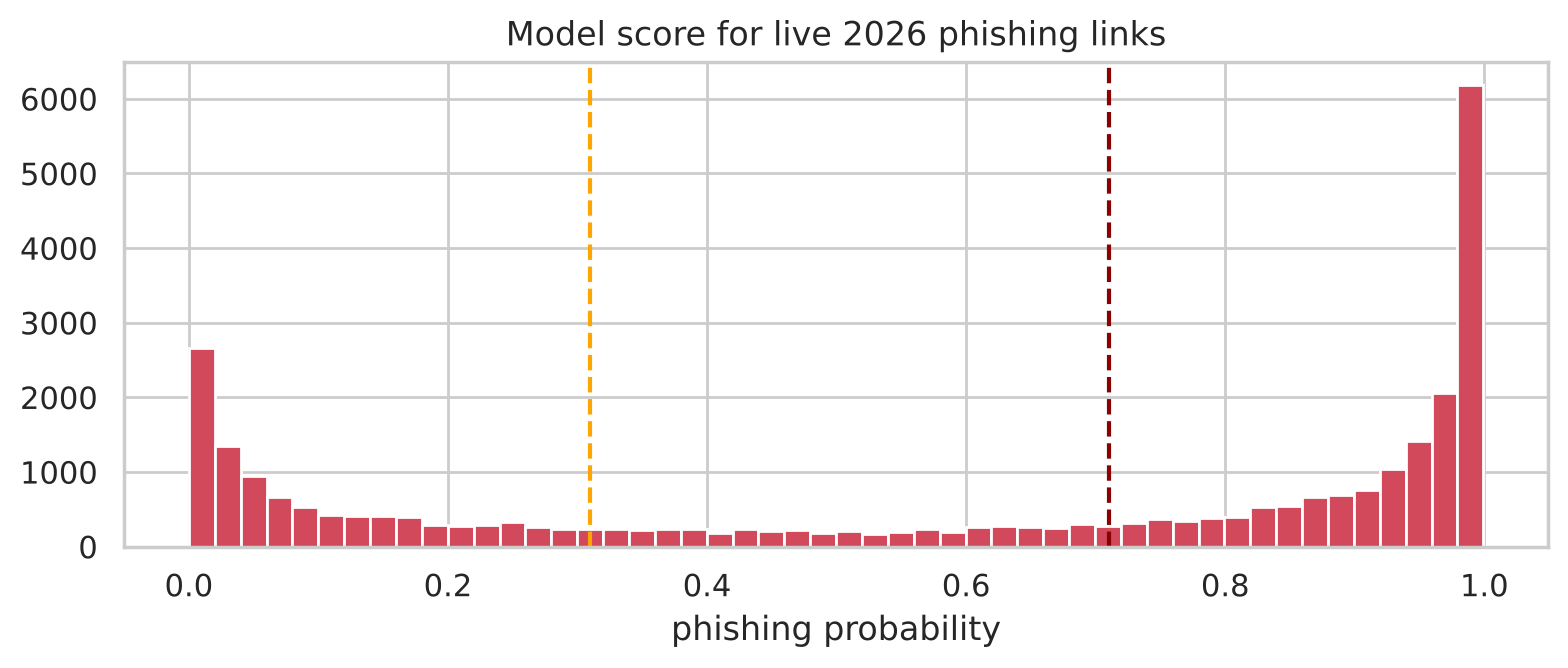

Examples the model scored as Safe:
28286    inv.nevieb.workers.dev/dfe.html?email=jeff_sch...
22991       cgbreaking.in/autorizacion-actualizar-prexcard
22582                  dolgovpayui.weebly.com/contact.html
26575    strange-chandrasekhar.107-172-156-131.plesk.pa...
20454                         metamasksi.azurewebsites.net
25316                              tourneysseason.otzo.com
22322                                      telegrams-h.com
10295    cas86t798-broad-cake-e386.wgwhiwgzpjw.workers....

5) Popular websites in the test set: 19,799 home pages
   flagged Suspicious or worse (>= 31): 0.97%   flagged Dangerous (>= 71): 0.17%


In [21]:
p_live = final_model.predict_proba(S_live)[:, 1]
live = pd.DataFrame([dict(rule=f"score >= {int(t*100)} ({lab})", detected=f"{(p_live >= t).mean():.1%}")
                     for t, lab in [(0.31, "Suspicious or Dangerous"), (0.5, "default threshold"), (0.71, "Dangerous")]])
print(f"4) LIVE 2026 phishing feed: {len(p_live):,} unseen phishing links"); display(live)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(p_live, bins=50, color="#D1495B"); ax.axvline(0.31, ls="--", c="orange"); ax.axvline(0.71, ls="--", c="darkred")
ax.set_title("Model score for live 2026 phishing links"); ax.set_xlabel("phishing probability")
plt.tight_layout(); plt.savefig(FIG / "live_feed.png", dpi=120); plt.show()
missed = LIVE.url[p_live < 0.31].sample(8, random_state=SEED)
print("Examples the model scored as Safe:"); print(missed.to_string())

# 5) False alarms on popular websites the model never saw (source T, test split)
mT = (test.src == "T").values
print(f"\n5) Popular websites in the test set: {mT.sum():,} home pages")
print(f"   flagged Suspicious or worse (>= 31): {(p_test[mT] >= .31).mean():.2%}   flagged Dangerous (>= 71): {(p_test[mT] >= .71).mean():.2%}")

**Honest limitation:** the links the model misses are mostly phishing pages hosted on big legitimate platforms
(cloud storage, form builders, site builders) or plain-looking domains. From the URL text alone they look like normal
links. D-WALL covers part of this gap with its other checks — following redirects and the optional page check that
looks for password/PIN forms — which is exactly why the app combines the ML score with those rules.

## 12. Speed test and saving the final model

In [22]:
bundle = dict(
    version="2.0.0",
    tfidf=tfidf, text_model=text_model, final_model=final_model,
    feature_names=FEATURE_NAMES,
    benign_p99=X_train[y_train == 0].quantile(0.99).to_dict(),
    best_params=dict(gradient_boosting=best_gb_params, text_C=text_grid.best_params_["C"]),
    metrics=dict(
        test_f1=float(f1_score(y_test, pred)), test_auc=float(roc_auc_score(y_test, p_test)),
        test_precision=float(precision_score(y_test, pred)), test_recall=float(recall_score(y_test, pred)),
        cv_f1_mean=float(cv_table.loc["mean", "f1"]), cv_f1_std=float(cv_table.loc["std", "f1"]),
        cross_dataset_f1_A_to_B=float(cross.f1[1]), live_recall_at_31=float((p_live >= .31).mean()),
        popular_sites_false_alarm_at_31=float((p_test[mT] >= .31).mean()),
        live_recall_at_50=float((p_live >= .5).mean()), n_train=int(len(train)), n_test=int(len(test)),
    ),
    sklearn_version=sklearn.__version__,
)
MODEL_PATH = ROOT / "backend" / "ml" / "dwall_model.joblib"
joblib.dump(bundle, MODEL_PATH, compress=3)
(ROOT / "ml" / "metrics.json").write_text(json.dumps(bundle["metrics"] | {"best_params": bundle["best_params"]}, indent=2))
print(f"Saved {MODEL_PATH.name}: {MODEL_PATH.stat().st_size/1e6:.1f} MB")
print(json.dumps(bundle["metrics"], indent=2))

Saved dwall_model.joblib: 2.9 MB
{
  "test_f1": 0.9207660856466537,
  "test_auc": 0.9940313633524569,
  "test_precision": 0.9478114478114478,
  "test_recall": 0.8952213574357687,
  "cv_f1_mean": 0.910594083609132,
  "cv_f1_std": 0.004602500590354126,
  "cross_dataset_f1_A_to_B": 0.7691359926074234,
  "live_recall_at_31": 0.6802,
  "popular_sites_false_alarm_at_31": 0.009747967069043892,
  "live_recall_at_50": 0.6099666666666667,
  "n_train": 469723,
  "n_test": 117431
}


In [23]:
# Load the model exactly like the API does, and check it on hand-picked examples
from ml.predictor import PhishingModel
model = PhishingModel.load(MODEL_PATH)

examples = ["https://www.google.com", "https://github.com/Iamshi-vissa/D-Wall", "https://en.wikipedia.org/wiki/Machine_learning",
            "https://paytm.com", "https://www.onlinesbi.sbi", "https://www.amazon.in/gp/cart/view.html",
            "https://www.irctc.co.in/nget/train-search", "https://www.phonepe.com/", "https://www.hdfcbank.com",
            "http://paytrn-kyc-refund.xyz/claim.php", "http://192.168.4.21/sbi/netbanking/login.php",
            "https://secure-login-icloud.com.verify-account.info/signin", "https://phonepe-cashback-reward.000webhostapp.com/upi/",
            "http://hdfc-bank.kyc-update-online.tk/verify?acc=user@gmail.com"]
display(pd.DataFrame({"url": examples, "phishing_probability": model.predict_proba(examples).round(3)}))
print("Why the scam examples were flagged:")
for u in examples[-5:]:
    print(" -", u, "\n     ", model.explain(u))

,url,phishing_probability
0,https://www.google.com,0.006
1,https://github.com/Iamshi-vissa/D-Wall,0.004
2,https://en.wikipedia.org/wiki/Machine_learning,0.000
3,https://paytm.com,0.003
4,https://www.onlinesbi.sbi,0.066
5,https://www.amazon.in/gp/cart/view.html,0.040
6,https://www.irctc.co.in/nget/train-search,0.005
7,https://www.phonepe.com/,0.005
8,https://www.hdfcbank.com,0.005
9,http://paytrn-kyc-refund.xyz/claim.php,0.961


Why the scam examples were flagged:
 - http://paytrn-kyc-refund.xyz/claim.php 
      ['The domain ending (TLD) is one that is cheap and often abused by scammers.', 'The link uses 3 words that are common in scams (login, verify, kyc, refund, ...).', 'Its spelling patterns closely match known phishing links (text model: 100%).']
 - http://192.168.4.21/sbi/netbanking/login.php 
      ['The link uses a raw IP address instead of a domain name.', 'The link uses 2 words that are common in scams (login, verify, kyc, refund, ...).', 'The domain name is full of numbers.', 'Its spelling patterns closely match known phishing links (text model: 100%).']
 - https://secure-login-icloud.com.verify-account.info/signin 
      ['The domain ending (TLD) is one that is cheap and often abused by scammers.', "A brand name appears in the address, but the site is not that brand's real domain.", 'The domain name looks random or machine-generated.', 'The link uses 5 words that are common in scams (login, verify,

In [24]:
# Scalability: how many URLs per second can one CPU core check?
bench = pd.concat([test.url] * 1).sample(20000, random_state=SEED).tolist()
t0 = time.time(); model.predict_proba(bench); dt = time.time() - t0
print(f"Scored {len(bench):,} URLs in {dt:.2f}s  ->  {len(bench)/dt:,.0f} URLs per second (single process)")
t0 = time.time(); model.predict_proba(["http://paytrn-kyc-refund.xyz/claim.php"]); print(f"Single URL latency: {(time.time()-t0)*1000:.1f} ms")

Scored 20,000 URLs in 2.42s  ->  8,275 URLs per second (single process)
Single URL latency: 4.5 ms


## Conclusion

* **Final model:** stacked ensemble (TF-IDF char n-gram Logistic Regression → tuned Histogram Gradient Boosting on
  44 URL features + text score). It beat every single model in the comparison table.
* **Validated** four ways: 5-fold CV (stable across folds), held-out test on both sources, a cross-dataset experiment
  that exposed dataset shift (and justified training on two sources), and 30,000 unseen live phishing links from 2026.
* **Scalable:** it needs only the URL text, scores thousands of URLs per second, and the API exposes a batch endpoint.
* **Course concepts used:** preprocessing & EDA, scaling, 5 classic models, bagging/boosting/XGBoost, GridSearchCV,
  stacking, PCA, K-Means with elbow/silhouette, confusion matrix, ROC-AUC, PR curve, F1, calibration, permutation
  importance.

**Limitations and future work:** phishing on trusted platforms is hard to catch from the URL alone; the training data is
mostly from public research datasets; a real threat-feed lookup (Google Safe Browsing) and WHOIS domain age would add
signals the model cannot see. Retraining regularly on fresh feeds would keep it current.